# Lean-13f : Corrélation de Bell du vide — OQP 12

**Navigation** : [<< Lean-13e Libre Arbitre](Lean-13e-Conway-Theoreme-Libre-Arbitre-Lean-Python.ipynb) | [Index](README.md) | [Lean-17a Noeuds >>](KNOTS/KNOTS-01-Conway-Proofs-Lean-Python.ipynb)

**Kernel** : Python 3 (numérique et lecture des sources du lake `conway_lean`)

***

### Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. Définir la corrélation de Bell d'un état entre deux algèbres locales (normalisation Summers-Werner) et ses deux bornes (classique 1, Tsirelson √2).
2. Calculer le corrélateur du vide à temps égal d'un champ scalaire massif et mesurer sa décroissance exponentielle.
3. Expliquer pourquoi la réponse au problème OQP 12 est **négative** pour les régions bornées : au-delà d'une séparation finie, la borne classique est atteinte.
4. Distinguer **intrication** (persiste à toute distance, Reeh-Schlieder / Verch-Werner) et **violation CHSH** (meurt à distance finie).
5. Lire le statut de la formalisation Lean 4 amont (six énoncés, audit d'axiomes) et le relier à l'organe CHSH de notre propre lake.

## Introduction

Les carnets [13b](Lean-13b-CHSH-Tsirelson-Native.ipynb), [13c](Lean-13c-CHSH-Landau-Saturation.ipynb) et
[13d](Lean-13d-CHSH-Indeterminisme-Native.ipynb) ont établi la frontière CHSH pour des systèmes à deux
qubits : borne classique 2, borne de Tsirelson 2√2, exécutées in-kernel. La question de ce carnet
est ce que cette frontière devient en **théorie quantique des champs** — non plus deux qubits, mais
le **vide** d'un champ, observé dans deux régions de l'espace-temps séparées spatialement.

L'histoire tient en trois temps :
1. **1985-1988** : Summers et Werner démontrent que le vide viole **maximalement** les inégalités
   de Bell (β = √2) sur des coins complémentaires et des double-cônes tangents.
2. **2005** : Verch et Werner démontrent que l'intrication du vide est **distillable à toute
   distance** ; et un trou de masse borne β ≤ 1 + 2e^(−m·t₁₂) pour des régions à distance positive.
   Mais cette borne tend vers 1 **sans jamais l'atteindre** — une violation, même infime,
   restait-elle possible à distance arbitrairement grande ?
3. **Octobre 2026** : le **problème 12** de la liste des problèmes quantiques ouverts de l'IQOQI
   de Vienne reçoit une réponse négative pour les régions bornées : au-delà d'une séparation
   finie L ≥ C\*·R, la corrélation de Bell du vide vaut **exactement 1** — la borne classique.

Ce carnet est le **digest pédagogique** de ce résultat : prérequis de QFT, définition de β,
inventaire de l'organe CHSH de notre lake, jouet structurel à deux qubits, énoncés, structure de
preuve, statut de formalisation. Aucun fichier `.lean` n'est ajouté : l'organe CHSH existant
(`Conway.CHSH*`, carnets 13b-13d) est invoqué par lecture de ses sources réelles.

### Prérequis
- [Lean-13b CHSH-Tsirelson](Lean-13b-CHSH-Tsirelson-Native.ipynb) (la frontière classique/quantique du score CHSH)
- Notions d'algèbre linéaire (valeurs propres, produit tensoriel, matrices de Pauli)
- Les aspects QFT sont introduits self-contained : aucun prérequis de théorie des champs

### Durée estimée : 45 minutes

## 1. La corrélation de Bell d'un état — la quantité centrale

Soient 𝔄 = 𝔄(O₁) et 𝔅 = 𝔄(O₂) les algèbres de von Neumann de deux régions spatialement
séparées (elles **commutent** : c'est la localité), et ω un état. Un observable mesurable dans
O₁ à valeurs dans [−1, 1] est une **contraction auto-adjointe** : A ∈ 𝔄, A = A\*, ‖A‖ ≤ 1.
Suivant Summers et Werner, la **corrélation de Bell** de ω est

$$\beta(\omega; \mathfrak{A}, \mathfrak{B}) \;=\; \sup \tfrac{1}{2}\left| \omega\big(A_0(B_0+B_1)+A_1(B_0-B_1)\big) \right|$$

le supremum étant pris sur les contractions auto-adjointes A₀, A₁ ∈ 𝔄 et B₀, B₁ ∈ 𝔅.
C'est **exactement le score CHSH** des carnets 13b-13d, à un facteur ½ près.

**Trois bornes immédiates** (chacune se démontre en une ligne) :

| Borne | Valeur | Preuve une-ligne |
|---|---|---|
| β ≥ 1 | toujours | prendre A₀ = B₀ = I, A₁ = B₁ = 0 |
| β ≤ 1 | modèles locaux cachés | \|a₀(b₀+b₁)+a₁(b₀−b₁)\| ≤ \|b₀+b₁\| + \|b₀−b₁\| ≤ 2 pour chaque λ |
| β ≤ √2 | Tsirelson (algèbres commutantes) | pour les réflexions, (A₀(B₀+B₁)+A₁(B₀−B₁))² = 4I − [A₀,A₁][B₀,B₁], de norme ≤ 8 |

La ligne de Tsirelson exploite l'identité de l'anticommutateur — **la même identité que celle
exécutée in-kernel dans le carnet 13c**. Si β > 1, les corrélations de ω entre les deux régions
ne sont reproductibles par aucun modèle local à variables cachées : c'est une **violation de
Bell**. Le supremum est inchangé si on le restreint aux réflexions (A² = B² = I), car toute
contraction auto-adjointe est une moyenne de réflexions et l'expression est affine en chaque
argument.

In [1]:
import sys
from pathlib import Path

import numpy as np
import scipy
from scipy.special import kv
import matplotlib
import matplotlib.pyplot as plt

print("Python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("scipy       :", scipy.__version__)
print("matplotlib  :", matplotlib.__version__)

# Le module d'utilitaires de la serie (meme outillage que Lean-13e).
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
import lean_notebook_utils as lnu
print("lean_notebook_utils : importe")

Python      : 3.13.16
numpy       : 2.2.6
scipy       : 1.18.1
matplotlib  : 3.11.2
lean_notebook_utils : importe


## 2. Prérequis QFT : le corrélateur du vide du champ scalaire massif

Le champ de l'énoncé est le **champ scalaire réel libre massif** en 3+1 dimensions, de masse
m > 0, dans son vide Ω. La seule quantité d'analyse dont nous aurons besoin est le corrélateur
à deux points à temps égal :

$$W(r) \;=\; \langle \Omega, \varphi(0, \mathbf{x})\, \varphi(0, \mathbf{y}) \Omega\rangle,
\qquad r = |\mathbf{x} - \mathbf{y}|,$$

qui se calcule exactement par intégration de Fourier (mesure invariante d³p / (2(2π)³ ω_𝐩)) :

$$W(r) \;=\; \frac{m\, K_1(m r)}{4 \pi^2 r},$$

où K₁ est la fonction de Bessel modifiée de seconde espèce. Deux régimes :
- **courte distance** (mr ≪ 1) : K₁(z) ~ 1/z, donc W(r) ~ 1/(4π²r²) — le comportement du champ
  sans masse ;
- **grande distance** (mr ≫ 1) : K₁(z) ~ √(π/2z) · e^(−z), donc W(r) ~ A(m) · r^(−3/2) · e^(−mr)
  — **décroissance exponentielle de taux m** : la longueur de corrélation du vide massif est
  ξ = 1/m.

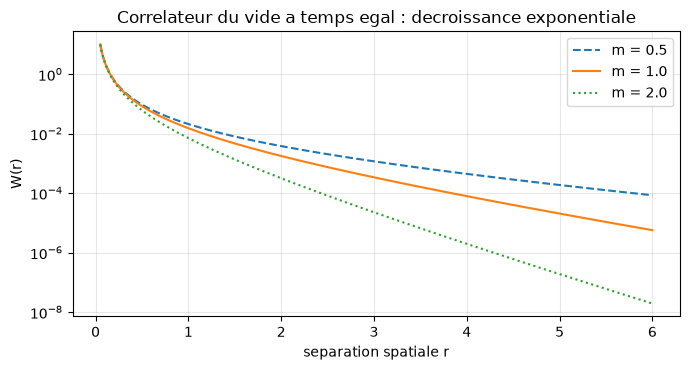

In [2]:
def wightman_egal_temps(r, m=1.0):
    """Correlateur du vide a temps egal du champ scalaire massif (3+1 D).

    <Omega, phi(0,x) phi(0,y) Omega> = W(|x-y|) = m K_1(m r) / (4 pi^2 r).
    """
    r = np.asarray(r, dtype=float)
    return m * kv(1, m * r) / (4.0 * np.pi**2 * r)

fig, ax = plt.subplots(figsize=(7.0, 3.8))
r = np.linspace(0.05, 6.0, 400)
for m, style in [(0.5, "--"), (1.0, "-"), (2.0, ":")]:
    ax.semilogy(r, wightman_egal_temps(r, m), style, label=f"m = {m}")
ax.set_xlabel("separation spatiale r")
ax.set_ylabel("W(r)")
ax.set_title("Correlateur du vide a temps egal : decroissance exponentiale")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Lecture du résultat

Plus la masse est grande, plus la décroissance est rapide — le **trou de masse** m gouverne la
portée des corrélations du vide. Quantifions le régime asymptotique : si W(r) ~ A·r^(−3/2)·e^(−mr),
alors le rapport W(r) / (A·r^(−3/2)·e^(−mr)) doit tendre vers 1.

In [3]:
def amplitude_asymptotique(m):
    """Prefacteur du regime asymptotique W(r) ~ A r^{-3/2} e^{-m r}."""
    return np.sqrt(m * np.pi) / (4.0 * np.pi**2 * np.sqrt(2.0))

print(f"{'r':>6}  {'W(r)':>12}  {'W(r) / asymptote':>18}")
for r in [0.5, 1.0, 2.0, 4.0, 8.0]:
    w = float(wightman_egal_temps(r, 1.0))
    asym = amplitude_asymptotique(1.0) * r ** (-1.5) * np.exp(-r)
    print(f"{r:>6.1f}  {w:>12.4e}  {w / asym:>18.4f}")
print()
print("Le rapport tend vers 1 : l'exponentielle e^{-mr} domine, le prefacteur")
print("en puissance r^{-3/2} ne fait que corriger.")

     r          W(r)    W(r) / asymptote
   0.5    8.3916e-02              1.5408
   1.0    1.5246e-02              1.3055
   2.0    1.7714e-03              1.1662
   4.0    7.9053e-05              1.0876
   8.0    4.9194e-07              1.0452

Le rapport tend vers 1 : l'exponentielle e^{-mr} domine, le prefacteur
en puissance r^{-3/2} ne fait que corriger.


### Exercice 1 — Longueur de corrélation effective

Entre r et 2r, le corrélateur décroît d'un facteur ~ e^(−mr) (le prefacteur r^(−3/2) ajoute un
facteur 2^(−3/2) constant). On définit le **taux effectif**

$$\tau_{\text{eff}}(r) \;=\; -\frac{\log\big(W(2r)/W(r)\big)}{r},$$

qui doit converger vers m quand r → ∞.

In [4]:
# Exercice 1 -- Longueur de correlation effective.
#
# TODO etudiant : completer taux_effectif ci-dessous, puis verifier sur la
# liste r = [1, 2, 4, 8, 16] que tau_eff(r) converge vers m = 1.
#
# Etape 1 : evaluer W aux deux points r et 2r (wightman_egal_temps accepte un scalaire).
# Etape 2 : retourner -log(rapport) / r.
# Indice : math.log ou np.log font l'affaire ; le resultat attendu pour r = 16
#          est proche de 1.07 (l'ecart est domine par le prefacteur r^(-3/2),
#          soit (3/2)ln(2)/r ; la correction K1 reste en 3/(16r^2)).

def taux_effectif(r, m=1.0):
    """Taux de decroissance effectif du correlateur entre r et 2r."""
    print("Exercice a completer")
    return None

# Verification attendue (decommentee apres completion) :
# for r in [1, 2, 4, 8, 16]:
#     print(r, taux_effectif(r))

## 3. L'organe CHSH du dépôt : inventaire des déclarations réelles

Ce carnet n'ajoute **aucun** fichier `.lean` : la frontière CHSH est déjà un organe du lake
`conway_lean`, consommé par les carnets 13b-13d. La règle du dépôt (organ-first) impose de
**lire les sources réelles** plutôt que de réimplémenter.

In [5]:
# Inventaire des declarations REELLES du lake conway_lean (lecture des sources).
projet = lnu.find_lean_project("conway_lean")
print("Projet lake   :", projet)
print("Plate-forme   : native =", lnu.is_native_platform(), "| Windows =", lnu.is_windows())
print()

import re

ROLES = {
    "score": "score CHSH d'une strategie locale deterministe",
    "score_factorization": "le score se factorise : |a0(b0+b1)+a1(b0-b1)| = 2 pour tout profil",
    "classical_abs_score": "frontiere classique etat par etat : |score| = 2 exactement",
    "classical_bound": "forme usuelle : |score| <= 2",
    "chshOperator": "operateur CHSH quantique (sigma-produits des 4 observables)",
    "classical_quantum_gap": "l'ecart strict 2 < 2*sqrt(2)",
    "classical_deterministic_bound_real": "frontiere deterministe, promuee en reels",
    "classical_randomized_bound_real": "frontiere randomisee (convexite), promuee en reels",
    "tsirelson_bound": "borne de Tsirelson 2*sqrt(2), contexte anneau etoile",
    "expectedScore": "score attendu d'une strategie randomisee",
    "randomized_bound": "toute strategie randomisee : |E[score]| <= 2 (convexite)",
}

fichiers = [
    "Conway/CHSH.lean",
    "Conway/CHSHQuantum.lean",
    "Conway/CHSHRandomized.lean",
]
pat = re.compile(r"^(?:theorem|def|lemma|abbrev)\s+([A-Za-z_][A-Za-z0-9_.']*)")
for rel in fichiers:
    chemin = Path(projet) / rel
    print(f"--- {rel} ---")
    for ligne in chemin.read_text(encoding="utf-8").splitlines():
        mobj = pat.match(ligne)
        if mobj:
            nom = mobj.group(1)
            role = ROLES.get(nom, "(voir la docstring du module)")
            print(f"  {nom:<40} {role}")
    print()

Projet lake   : D:\dev\CoursIA-26488-bellvide\MyIA.AI.Notebooks\SymbolicAI\Lean\GOL\conway_lean
Plate-forme   : native = False | Windows = True

--- Conway/CHSH.lean ---
  Outcome.value                            (voir la docstring du module)
  Outcome.value_sq                         (voir la docstring du module)
  score                                    score CHSH d'une strategie locale deterministe
  score_factorization                      le score se factorise : |a0(b0+b1)+a1(b0-b1)| = 2 pour tout profil
  classical_abs_score                      frontiere classique etat par etat : |score| = 2 exactement
  classical_bound                          forme usuelle : |score| <= 2

--- Conway/CHSHQuantum.lean ---
  chshOperator                             operateur CHSH quantique (sigma-produits des 4 observables)
  sqrt_two_cubed                           (voir la docstring du module)
  classical_quantum_gap                    l'ecart strict 2 < 2*sqrt(2)
  classical_deterministic_bou

### Lecture de l'inventaire

L'organe couvre exactement les trois volets des carnets compagnons :

| Module | Volet | Carnet consommateur |
|---|---|---|
| `Conway.CHSH` | frontière classique déterministe (\|score\| = 2 exactement) | 13b, 13d |
| `Conway.CHSHQuantum` | écart classique/quantique et borne de Tsirelson 2√2 | 13b, 13c |
| `Conway.CHSHRandomized` | extension par convexité aux stratégies randomisées (\|E[score]\| ≤ 2) | 13d |

### Le pont de normalisation

Ces modules mesurent |ω(A₀(B₀+B₁)+A₁(B₀−B₁))| ; la littérature vide-Bell (Summers-Werner,
OQP 12) mesure la même quantité **divisée par 2**. Les deux échelles coexistent dans le dépôt —
d'où l'importance de toujours dire laquelle on utilise :

In [6]:
print(f"{'':<22}{'Grenier du depot (13b-13d)':<34}{'Summers-Werner (OQP 12)'}")
print("-" * 88)
print(f"{'Quantite':<22}{'|omega(A0(B0+B1)+A1(B0-B1))|':<34}{'beta = sup 1/2 |omega(...)|'}")
print(f"{'Borne classique':<22}{'2':<34}{'1'}")
print(f"{'Borne de Tsirelson':<22}{'2 * sqrt(2) = 2.8284...':<34}{'sqrt(2) = 1.4142...'}")
print(f"{'Lien':<22}{'beta = score / 2 (le facteur 1/2 de la definition)'}")
print()
print("Dans la suite de ce carnet : normalisation Summers-Werner (bornes 1 et sqrt(2)),")
print("parce que c'est celle de l'enonce OQP 12 et de toute la litterature citee.")

                      Grenier du depot (13b-13d)        Summers-Werner (OQP 12)
----------------------------------------------------------------------------------------
Quantite              |omega(A0(B0+B1)+A1(B0-B1))|      beta = sup 1/2 |omega(...)|
Borne classique       2                                 1
Borne de Tsirelson    2 * sqrt(2) = 2.8284...           sqrt(2) = 1.4142...
Lien                  beta = score / 2 (le facteur 1/2 de la definition)

Dans la suite de ce carnet : normalisation Summers-Werner (bornes 1 et sqrt(2)),
parce que c'est celle de l'enonce OQP 12 et de toute la litterature citee.


## 4. La question OQP 12, en termes de β

**Ce qui était connu avant octobre 2026 :**

1. **Le vide viole maximalement sur des coins** : Summers et Werner ont prouvé β = √2 pour le
   vide d'un champ massif libre sur des coins complémentaires ({x₁ > \|x₀\|} et son miroir
   spatial) et sur des double-cônes **tangents**. Ces régions se touchent : la séparation
   est nulle.
2. **L'intrication persiste à toute distance** : par le théorème de Reeh-Schlieder, le vide est
   intriqué à travers **toute paire** de régions spatialement séparées, et Verch-Werner ont
   montré que cette intrication est **distillable à toute distance** — des paires intriquées
   standard peuvent en être extraites par opérations locales et communication classique.
3. **Un trou de masse borne la violation** : pour des régions à distance positive, β ≤ 1 + 2e^(−m·t₁₂),
   où t₁₂ est le plus grand temps pendant lequel une région peut être décalée en restant
   spatialement séparée de l'autre. Cette borne **tend vers 1 sans l'atteindre**.

**La question ouverte** (problème 12, IQOQI Vienne) : une violation, même infime, même portée
par des événements de probabilité arbitrairement petite, subsiste-t-elle pour des régions
bornées arbitrairement éloignées ? *« Decide whether some (necessarily small) violation of the
inequalities is possible for regions arbitrarily far apart. For definiteness, consider a massive
scalar free relativistic Bose field. »*

**Pourquoi la question est subtile** : l'intrication (point 2) ne suffit pas à produire une
violation CHSH. Intrication et violation sont deux propriétés **strictement emboîtées** — et le
jouet structurel de la section suivante le montre sur un exemple à deux qubits.

## 5. Jouet structurel : une famille à deux qubits

Pour donner un contenu numérique à la distinction intrication / violation, prenons la famille
d'états à deux qubits de matrice de corrélation T = diag(c, c, −c) — la famille la plus simple
dont β et l'intrication se calculent exactement. Elle modélise une paire de régions dont les
corrélations décroissent avec la séparation L via c = e^(−L/ξ), ξ = 1/m :

$$\rho(c) \;=\; \tfrac{1}{4}\Big( I \otimes I + c\, \sigma_x \otimes \sigma_x + c\, \sigma_y \otimes \sigma_y - c\, \sigma_z \otimes \sigma_z \Big).$$

À c = 1 c'est un état maximalement intriqué (les valeurs propres en base de Bell sont
(1+3c)/4 et (1−c)/4 trois fois — à c = 1, seule la première survit).

In [7]:
PAULI = {
    "x": np.array([[0, 1], [1, 0]], dtype=complex),
    "y": np.array([[0, -1j], [1j, 0]], dtype=complex),
    "z": np.array([[1, 0], [0, -1]], dtype=complex),
}
I2 = np.eye(2, dtype=complex)

def etat_bell_diagonal(c):
    """Etat a deux qubits de matrice de correlation T = diag(c, c, -c).

    Valeurs propres (base de Bell) : (1 + 3c)/4 et (1 - c)/4 trois fois.
    """
    return 0.25 * (
        np.kron(I2, I2)
        + c * np.kron(PAULI["x"], PAULI["x"])
        + c * np.kron(PAULI["y"], PAULI["y"])
        - c * np.kron(PAULI["z"], PAULI["z"])
    )

for c in [1.0, 0.5, 1.0 / 3.0, 0.0]:
    rho = etat_bell_diagonal(c)
    print(f"c = {c:.4f} -> valeurs propres {np.round(np.linalg.eigvalsh(rho), 6)}")

c = 1.0000 -> valeurs propres [0. 0. 0. 1.]
c = 0.5000 -> valeurs propres [0.125 0.125 0.125 0.625]
c = 0.3333 -> valeurs propres [0.166667 0.166667 0.166667 0.5     ]
c = 0.0000 -> valeurs propres [0.25 0.25 0.25 0.25]


### 5.1 β par le critère d'Horodecki

Pour un état à deux qubits de matrice de corrélation T (3×3), le critère d'Horodecki donne la
violation CHSH maximale **exactement** : β = √(m₁ + m₂), où m₁ ≥ m₂ sont les deux plus grandes
valeurs propres de TᵀT. (C'est le théorème derrière la borne exécutée in-kernel dans 13b/13c.)

In [8]:
def beta_horodecki(T):
    """Correlation de Bell beta d'un etat a deux qubits (critere d'Horodecki).

    beta = sqrt(m1 + m2), m1 >= m2 les deux plus grandes valeurs propres
    de T^T T. Borne classique 1, Tsirelson sqrt(2).
    """
    valeurs = np.linalg.eigvalsh(T.T @ T)  # tri croissant
    m1, m2 = valeurs[-1], valeurs[-2]
    return float(np.sqrt(m1 + m2))

print(f"{'c':>8}  {'beta':>8}   seuils : sqrt(2) c > 1 <=> c > 1/sqrt(2)")
for c in [1.0, 1.0 / np.sqrt(2.0), 0.5, 0.2]:
    T = np.diag([c, c, -c])
    marque = " <- borne classique" if abs(c - 1 / np.sqrt(2)) < 1e-9 else ""
    print(f"{c:>8.4f}  {beta_horodecki(T):>8.4f}{marque}")
print()
print("Pour cette famille : beta = sqrt(2) * c, la violation CHSH disparait")
print("des que c <= 1/sqrt(2), c'est-a-dire L >= xi * ln(sqrt(2)).")

       c      beta   seuils : sqrt(2) c > 1 <=> c > 1/sqrt(2)
  1.0000    1.4142
  0.7071    1.0000 <- borne classique
  0.5000    0.7071
  0.2000    0.2828

Pour cette famille : beta = sqrt(2) * c, la violation CHSH disparait
des que c <= 1/sqrt(2), c'est-a-dire L >= xi * ln(sqrt(2)).


### 5.2 L'intrication par la concurrence

La **concurrence** C(ρ) (recette de Wootters) mesure l'intrication : C = 0 pour un état
séparable, C = 1 pour un état maximalement intriqué. La recette numérique : valeurs propres λᵢ
de R = ρ·ρ̃ (ρ̃ = (σy⊗σy)·ρ̄·(σy⊗σy)), puis C = max(0, √λ₁ − √λ₂ − √λ₃ − √λ₄).

In [9]:
def concurrence(rho):
    """Concurrence numerique (recette de Wootters)."""
    yy = np.kron(PAULI["y"], PAULI["y"])
    rho_tilde = yy @ rho.conj() @ yy
    lmbda = np.linalg.eigvals(rho @ rho_tilde).real
    lmbda = np.clip(np.sort(lmbda)[::-1], 0.0, None)
    racines = np.sqrt(lmbda)
    return float(max(0.0, racines[0] - racines[1] - racines[2] - racines[3]))

print(f"{'c':>8}  {'C':>8}   seuils : C > 0 <=> c > 1/3")
for c in [1.0, 0.5, 1.0 / 3.0, 0.2]:
    print(f"{c:>8.4f}  {concurrence(etat_bell_diagonal(c)):>8.4f}")
print()
print("Pour cette famille : C = max(0, (3c - 1)/2), l'intrication disparait")
print("des que c <= 1/3, c'est-a-dire L >= xi * ln(3).")

       c         C   seuils : C > 0 <=> c > 1/3


  1.0000    1.0000
  0.5000    0.2500
  0.3333    0.0000
  0.2000    0.0000

Pour cette famille : C = max(0, (3c - 1)/2), l'intrication disparait
des que c <= 1/3, c'est-a-dire L >= xi * ln(3).


### 5.3 Les deux seuils ne coïncident pas

Mettons les deux courbes sur le même axe, en fonction de la séparation L (avec ξ = 1) :

- **violation CHSH** : β(L) = √2·e^(−L) franchit 1 à **L\* = ξ·ln(√2) ≈ 0.347** ;
- **intrication** : C(L) = max(0, (3e^(−L) − 1)/2) atteint 0 à **L\*\* = ξ·ln(3) ≈ 1.099**.

Entre les deux : la **fenêtre intriqué-sans-violation** — l'état est intriqué mais ne viole
plus CHSH. C'est la separation conceptuelle que le théorème OQP 12 réalise dans le vide.

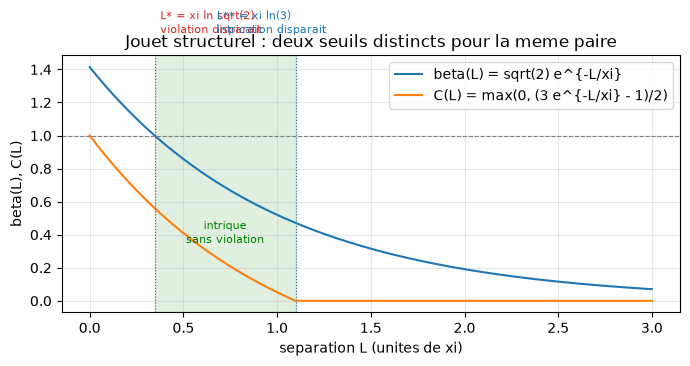

In [10]:
xi = 1.0  # longueur de correlation (xi = 1/m)
L = np.linspace(0.0, 3.0, 600)
c_L = np.exp(-L / xi)
beta_L = np.sqrt(2.0) * c_L
C_L = np.maximum(0.0, (3.0 * c_L - 1.0) / 2.0)

fig, ax = plt.subplots(figsize=(7.0, 3.8))
ax.plot(L, beta_L, label="beta(L) = sqrt(2) e^{-L/xi}")
ax.plot(L, C_L, label="C(L) = max(0, (3 e^{-L/xi} - 1)/2)")
ax.axhline(1.0, color="gray", lw=0.8, ls="--")
L1, L2 = np.log(np.sqrt(2.0)), np.log(3.0)
ax.axvspan(L1, L2, alpha=0.12, color="green")
ax.axvline(L1, color="tab:red", lw=0.8, ls=":")
ax.axvline(L2, color="tab:blue", lw=0.8, ls=":")
ax.text(L1 + 0.03, 1.62, "L* = xi ln sqrt(2)\nviolation disparait", fontsize=8, color="tab:red")
ax.text(L2 - 0.42, 1.62, "L** = xi ln(3)\nintrication disparait", fontsize=8, color="tab:blue")
ax.text((L1 + L2) / 2, 0.35, "intrique\nsans violation", fontsize=8,
        color="green", ha="center")
ax.set_xlabel("separation L (unites de xi)")
ax.set_ylabel("beta(L), C(L)")
ax.set_title("Jouet structurel : deux seuils distincts pour la meme paire")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Lecture du résultat

L'intrication **survit** à la violation CHSH : la fenêtre verte [ln(√2), ln 3) est exactement
l'écart entre les deux notions. Le théorème OQP 12 dit que dans le vide du champ massif, la
violation CHSH meurt à **séparation finie** pour des régions bornées — pendant que
l'intrication, elle, subsiste à toute distance (Reeh-Schlieder, Verch-Werner). Le jouet rend
les deux phénomènes visibles sur un système de dimension 4 ; le théorème les établit dans une
théorie à une infinité de degrés de liberté, où β est un supremum sur **tous** les observables
bornés des deux régions — y compris des événements de probabilité arbitrairement petite.

### Exercice 2 — Le seuil de violation L\*

La théorie dit L\* = ξ·ln(√2). Retrouvez-le numériquement.

In [11]:
# Exercice 2 -- Seuil de violation L*.
#
# TODO etudiant : completer seuil_violation pour retourner le L ou
# beta(L) = sqrt(2) e^{-L} franchit 1, par recherche de racine numerique.
#
# Etape 1 : definir f(L) = sqrt(2) * exp(-L) - 1.
# Etape 2 : retourner scipy.optimize.brentq(f, 0.0, 5.0).
# Indice : verifier que le resultat vaut ln(sqrt(2)) a la precision machine.

from scipy.optimize import brentq

def seuil_violation():
    """Separation L ou beta(L) = sqrt(2) e^{-L} franchit la borne classique 1."""
    print("Exercice a completer")
    return None

# Verification attendue (decommentee apres completion) :
# Lstar = seuil_violation()
# print(Lstar, np.log(np.sqrt(2.0)))

### Exercice 3 — Intrication de la famille diag(c, c, −c)

Un état à matrice de corrélation diagonale (base de Bell) est séparable si et seulement si
**toutes** ses valeurs propres sont ≤ 1/2 — pour notre famille : (1+3c)/4 ≤ 1/2, i.e. c ≤ 1/3.

In [12]:
# Exercice 3 -- Intrication de la famille diag(c, c, -c).
#
# TODO etudiant : completer est_intrique(c) (True ssi l'etat est intrique),
# puis borner numeriquement la fenetre [L*, L**) ou l'etat est intrique
# SANS violer CHSH.
#
# Etape 1 : construire rho = etat_bell_diagonal(c).
# Etape 2 : calculer la plus grande valeur propre (np.linalg.eigvalsh trie croissant).
# Etape 3 : comparer a 1/2.
# Indice : la fenetre attendue est [ln(sqrt(2)), ln(3)) en unites de xi ;
#          on peut la balayer par L = np.linspace(0, 3, 31).

def est_intrique(c):
    """True ssi l'etat de matrice T = diag(c, c, -c) est intrique."""
    print("Exercice a completer")
    return None

# Verification attendue (decommentee apres completion) :
# for c in [0.2, 1.0/3.0, 0.5, 1.0]:
#     print(c, est_intrique(c))

## 6. Le théorème : coupure à séparation finie

**Théorème 1 (coupure à séparation finie, Turturean 2026).** Il existe une constante finie
C\* > 2, **indépendante de la masse m et du rayon R**, telle que

$$\forall m, R > 0, \quad L \ge C^* R \;\Longrightarrow\; \beta_m(R, L) = 1,$$

où β_m(R, L) est la corrélation de Bell du vide entre l'algèbre du double-cône D_R et celle de
son translaté D_R + (0, L·e₁).

**Corollaire 1 (régions bornées fixées).** Pour toute masse m > 0, toute paire de régions
bornées fixées O₁, O₂ et toute direction spatiale fixée, la corrélation de Bell du vide de
𝔄_m(O₁) et de l'algèbre du translaté de O₂ vaut **1** pour tout translaté assez grand.

**Deux variantes supplémentaires** accompagnent l'énoncé : une version **uniforme** (un seul
seuil D pour toutes les directions spatiales du translaté), et une **garde de non-vacuité**
(l'algèbre locale de toute région ouverte non vide est non commutative — le théorème ne peut
pas être trivialisé par une algèbre commutative).

La réponse au problème 12 est donc **négative pour les régions bornées** : ce que le théorème
exclut, c'est une violation CHSH — si petite et si rare soient ses événements — entre régions
bornées assez éloignées.

### Structure de la preuve

La preuve compare le vide à **l'état produit de ses restrictions** aux deux régions — l'état qui
a la même physique locale et **aucune corrélation** entre les régions (et qui de ce fait
satisfait trivialement β = 1) :

1. **Réductions (section II)** : mise en place du champ à temps t = 0, deux réductions ramènent
   l'étude aux observables bornés des deux bases ;
2. **Du proche au produit vers la borne classique (section III)** : si ω est assez proche de
   l'état produit, alors β(ω) = 1 — la borne classique devient une **continuité** de la
   non-corrélation ;
3. **La proximité à grande séparation (sections IV-V)** : un théorème de **clustering**
   (théorème 2 : bornes à deux événements) établit que le vide approche l'état produit à un taux
   polynomial en la séparation, **uniformément en la masse** — c'est le cœur technique, où la
   décroissance exponentielle du corrélateur (section 2 de ce carnet) devient un contrôle en
   norme trace sur la différence de covariance ;
4. **L'optimisation géométrique (section VI)** : le taux polynomial, réparti sur le rapport L/R,
   donne la forme finale C\*·R.

### Limites de ce qui est prouvé

- Le théorème fournit une séparation **suffisante**, pas un seuil **optimal** : il ne localise
  pas la plus petite séparation donnant β = 1 ;
- la constante C\* est finie mais **non explicite** ;
- restent **ouverts** : les régions qui **grandissent** avec la séparation, et les **coins
  (wedges) à écart positif** — l'énoncé ne contredit pas Summers-Werner (coins complémentaires,
  séparation nulle).

### Ce que β = 1 ne dit pas

β = 1 n'est **pas** « plus d'intrication » : par Reeh-Schlieder, le vide reste intriqué à travers
les deux régions, et cette intrication reste **distillable à toute distance** (Verch-Werner).
La borne classique porte uniquement sur la quantité CHSH **sans filtrage local** ; les violations
obtenues après filtrage local de sondes couplées (Reznik-Retzker-Silman) concernent un état
post-sélectionné et ne sont pas en cause dans le problème 12.

## 7. Statut de la formalisation Lean 4 amont

Le résultat a été **formalisé en Lean 4 par des agents IA** et vérifié par le noyau de Lean ;
le dépôt public est `physical-superintelligence/oqp-batch-2026`, sous-module
`oqp12-vacuum-bell-correlations/lean` (toolchain `v4.35.0-rc4` ; le nôtre est `v4.33.0` — aucun
port n'a été tenté dans ce carnet, et ce n'est pas son objet).

La bibliothèque amont est vaste — **plus d'un millier de fichiers Lean** au dossier
`oqp12-vacuum-bell-correlations/lean` (inventaire mesuré le 14/11/2026 par l'API GitHub du dépôt).

Le fichier `Challenge.lean` y est l'**énoncé de référence** : il n'importe que Mathlib, les
définitions y sont copiées verbatim du module des définitions, et chaque théorème y est suivi
de `sorry` **par construction** — les preuves vivent dans `Solution.lean`, et un comparateur
vérifie que `Solution` prouve exactement ces théorèmes avec les seuls axiomes `propext`,
`Quot.sound` et `Classical.choice` (audit d'axiomes du 21/10/2026, commit
`6a91bb4b256579eb39f6a5f08f2cb0c1e9bc94e5`).

In [13]:
# Les six enonces du fichier Challenge.lean (statement of record), cites depuis
# la copie amont (commit 6a91bb4b, 21/10/2026). Chaque enonce y est suivi de
# `sorry` : les preuves vivent dans Solution.lean, verifiees par comparateur.
OQP12_CHALLENGE = [
    ("no_chsh_violation_far_apart", 171,
     "enonce vedette : pas de violation CHSH au-dela d'une separation finie"),
    ("theorem_1_1", 190,
     "Theoreme 1 : seuil universel L >= C* R implique beta_m(R, L) = 1"),
    ("corollary_1_2", 208,
     "Corollaire 1 : regions bornees fixees, translation assez grande"),
    ("freeFieldVacuum_exists", 226,
     "non-vacuite : un systeme de Weyl du vide existe pour toute masse"),
    ("no_chsh_violation_far_apart_uniform", 236,
     "version uniforme : un seuil D pour toutes les directions spatiales"),
    ("localAlgebra_open_nonabelian", 254,
     "garde-fou : les algebres locales ouvertes sont non commutatives"),
]

print("Fichier Challenge.lean (statement of record), six enonces :")
for nom, ligne, role in OQP12_CHALLENGE:
    print(f"  ligne {ligne:>3} : {nom:<40} {role}")
print()
print("Le modele : Spacetime = R x R^3, doubleCone a R = { |x0| + |x| < R },")
print("FreeFieldVacuum m H = systeme de Weyl du vide (operateurs W(F), vecteur")
print("Omega cyclique, etat quasi-libre centre), localAlgebra V O = algebre de")
print("von Neumann engendree par les W(F) a support dans O.")

Fichier Challenge.lean (statement of record), six enonces :
  ligne 171 : no_chsh_violation_far_apart              enonce vedette : pas de violation CHSH au-dela d'une separation finie
  ligne 190 : theorem_1_1                              Theoreme 1 : seuil universel L >= C* R implique beta_m(R, L) = 1
  ligne 208 : corollary_1_2                            Corollaire 1 : regions bornees fixees, translation assez grande
  ligne 226 : freeFieldVacuum_exists                   non-vacuite : un systeme de Weyl du vide existe pour toute masse
  ligne 236 : no_chsh_violation_far_apart_uniform      version uniforme : un seuil D pour toutes les directions spatiales
  ligne 254 : localAlgebra_open_nonabelian             garde-fou : les algebres locales ouvertes sont non commutatives

Le modele : Spacetime = R x R^3, doubleCone a R = { |x0| + |x| < R },
FreeFieldVacuum m H = systeme de Weyl du vide (operateurs W(F), vecteur
Omega cyclique, etat quasi-libre centre), localAlgebra V O = algebre de


### Le contraste avec notre lake

Là où l'amont livre un **énoncé de référence** à prouver (six `sorry` par design), notre lake
`conway_lean` porte ses preuves complètes. Mesurons-le avec l'organe du dépôt :

In [14]:
# Organe reel du depot : comptage des sorry authentiques du lake conway_lean.
# (Pure lecture de fichiers -- aucun lake build ici ; la preuve de build des
# PR Lean de ce depot est le runner CI.)
nb_sorry = lnu.count_sorry(str(projet))
print(f"conway_lean : {nb_sorry} sorry dans les sources auteurs")
print()
print("Detail mesure : les 2 occurrences sont la paire FR/EN d'un MEME sorry")
print("documente (HashlifeMarginFragment.lean:171 et son jumeau _en:171,")
print("acceptation INTRINSIC ai-01) -- 1 sorry logique, hors des modules CHSH.")
print("Les modules Conway.CHSH / CHSHQuantum / CHSHRandomized portent 0 sorry,")
print("audites in-kernel dans les carnets 13b (axiomes standards, pas de sorryAx).")

conway_lean : 2 sorry dans les sources auteurs

Detail mesure : les 2 occurrences sont la paire FR/EN d'un MEME sorry
documente (HashlifeMarginFragment.lean:171 et son jumeau _en:171,
acceptation INTRINSIC ai-01) -- 1 sorry logique, hors des modules CHSH.
Les modules Conway.CHSH / CHSHQuantum / CHSHRandomized portent 0 sorry,
audites in-kernel dans les carnets 13b (axiomes standards, pas de sorryAx).


## 8. Honnêteté : ce qu'il faut garder à l'esprit

1. **Prépublication** : la lettre (22/10/2026) et le manuscrit (21/10/2026) ne sont pas
   revisés par des pairs au sens journal — le referee report mentionné (Ning Bao, prestataire
   de PSI) est un rapport commandité, pas une review d'éditeur. La formalisation Lean 4
   vérifiée par le noyau est le renfort le plus fort de crédibilité du résultat.
2. **Produit par des agents IA** : les workflows automatisés de recherche et formalisation de
   PSI (Physical Superintelligence) ont produit les résultats ; l'auteur humain a dirigé le
   travail et demandé les révisions.
3. **Constante non explicite** : le C\* du théorème est finie mais non calculée — le théorème
   est d'existence, pas effectif.
4. **Pas de seuil optimal** : la plus petite séparation donnant β = 1 n'est pas localisée.
5. **Cas ouverts** : régions croissant avec la séparation, coins à écart positif.
6. **Classement catalogue, cité tel quel** : OQP 12 reste listé comme **ouvert** sur le
   catalogue IQOQI au relevé du 14/11/2026 — la liste « Solved By » ne mentionne aucune des
   cinq entrées du lot PSI. Le catalogue n'a donc pas (encore) acté la réponse ; ce carnet
   digère une réponse **amont existante**, il ne déclare pas le problème résolu.
7. **Classement interne** : ce carnet entre comme digest de branche 13 (frontières CHSH),
   voisin de la section 9 de Lean-13 (digest CGLMP, OQP 27).

## Résumé

### Concepts clés

| Concept | Définition | Rôle |
|---------|------------|------|
| **β(ω; 𝔄, 𝔅)** | sup ½\|ω(A₀(B₀+B₁)+A₁(B₀−B₁))\| sur les contractions auto-adjointes | La quantité de Summers-Werner (bornes 1 et √2) |
| **Corrélateur du vide** | W(r) = m·K₁(mr)/(4π²r) | Décroissance exponentielle de taux m (ξ = 1/m) |
| **Reeh-Schlieder / Verch-Werner** | Le vide est intriqué — et distillable — à toute distance | Ce qui **reste** quand β = 1 |
| **Théorème 1** | ∃C\*>2 : L ≥ C\*R ⟹ β_m(R,L) = 1 | La coupure à séparation finie (réponse négative à OQP 12) |
| **Fenêtre intriqué-sans-violation** | ξ·ln(√2) ≤ L < ξ·ln(3) sur le jouet | Intrication ⊋ violation, visible en dimension 4 |

### Le tableau des sources

| Source | Ce qu'elle apporte |
|---|---|
| Summers-Werner 1985-1988 | β = √2 sur coins complémentaires et double-cônes tangents |
| Verch-Werner 2005 | Intrication du vide distillable à toute distance |
| Summers-Werner 1987 / Summers 2011 | β ≤ 1 + 2e^(−m·t₁₂) à distance positive |
| IQOQI Vienne, problème 12 (2005/2023) | L'énoncé ouvert |
| Turturean 2026 (lettre + manuscrit) | La réponse négative : Théorème 1 + Corollaire 1 |
| Dépôt PSI oqp-batch-2026 | Formalisation Lean 4 vérifiée par le noyau |

### Ce qui a été exécuté dans ce carnet

Lecture des sources réelles du lake `conway_lean` (modules `Conway.CHSH`, `CHSHQuantum`,
`CHSHRandomized`), numérique scipy/matplotlib (fonction de Bessel K₁, valeurs propres,
brentq), comptage `sorry` par `lean_notebook_utils`. **Aucune sortie n'a été écrite à la
main.** Aucun `lake build` n'a été lancé depuis ce carnet : sur ce dépôt, la preuve de build
d'une PR Lean est le runner CI. Les six énoncés amont sont cités depuis le fichier
`Challenge.lean` du dépôt PSI (commit `6a91bb4b`, 21/10/2026), consulté en lecture seule.

### Références

1. **M. Turturean**, *The vacuum Bell correlation of the massive free scalar field attains the
   classical bound*, lettre du 22/10/2026 (OQP). Copie archivée : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Physics\2026 - Turturean - The vacuum Bell correlation of the massive free scalar field attains the classical bound (OQP letter, 22 Oct 2026).pdf`
2. **M. Turturean**, manuscrit complet du 21/10/2026. Copie archivée : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Physics\2026 - Turturean - The vacuum Bell correlation of the massive free scalar field attains the classical bound (full manuscript, 21 Oct 2026).pdf`
3. **S. J. Summers, R. F. Werner**, *The vacuum violates Bell's inequalities*, Phys. Lett. A
   **110**, 257 (1985), doi:10.1016/0375-9601(85)90093-3.
4. **S. J. Summers, R. F. Werner**, *Bell's inequalities and quantum field theory. I. General
   setting*, J. Math. Phys. **28**, 2440 (1987), doi:10.1063/1.527733 ; *II. Bell's inequalities
   are maximally violated in the vacuum*, J. Math. Phys. **28**, 2448 (1987),
   doi:10.1063/1.527734.
5. **R. Verch, R. F. Werner**, *Distillability and positivity of partial transposes in general
   quantum field systems*, Rev. Math. Phys. **17**, 545 (2005), doi:10.1142/S0129055X05002364,
   arXiv:quant-ph/0403089.
6. **IQOQI Vienna**, *Open Quantum Problems, Problem 12* :
   https://oqp.iqoqi.oeaw.ac.at/bell-inequalities-for-long-range-vacuum-correlations
   (copie archivée du 29/10/2023 sur web.archive.org).
7. Dépôt de formalisation : `github.com/physical-superintelligence/oqp-batch-2026`,
   sous-dossier `oqp12-vacuum-bell-correlations/lean` (commit `6a91bb4b`).

### Liens

- [Lean-13b CHSH-Tsirelson](Lean-13b-CHSH-Tsirelson-Native.ipynb) : la borne de Tsirelson exécutée in-kernel
- [Lean-13c Landau-Saturation](Lean-13c-CHSH-Landau-Saturation.ipynb) : l'identité de l'anticommutateur, exécutée
- [Lean-13d Indeterminisme](Lean-13d-CHSH-Indeterminisme-Native.ipynb) : la route statistique vers l'indéterminisme
- [Lean-13 Kochen-Specker](Lean-13-Kochen-Specker.ipynb) : le noyau combinatoire (section 9 : digest CGLMP, OQP 27)
- [Lean-13e Libre Arbitre](Lean-13e-Conway-Theoreme-Libre-Arbitre-Lean-Python.ipynb) : SPIN/TWIN/MIN

***

**Navigation** : [<< Lean-13e Libre Arbitre](Lean-13e-Conway-Theoreme-Libre-Arbitre-Lean-Python.ipynb) | [Index](README.md) | [Lean-17a Noeuds >>](KNOTS/KNOTS-01-Conway-Proofs-Lean-Python.ipynb)